# Visualizing Errors

For any scientific measurement, **accurate accounting for errors** is nearly as important, if not more important, than accurate reporting of the number itself.
For example, imagine that I am using some astrophysical observations to estimate the Hubble Constant, the local measurement of the expansion rate of the Universe.
I know that the current literature suggests a value of around 71 (km/s)/Mpc, and I measure a value of 74 (km/s)/Mpc with my method. Are the values consistent? The only correct answer, given this information, is this: there is no way to know.

Suppose I augment this information with reported uncertainties: the current literature suggests a value of around 71 $\pm$ 2.5 (km/s)/Mpc, and my method has measured a value of 74 $\pm$ 5 (km/s)/Mpc. Now are the values consistent? That is a question that can be quantitatively answered.

In visualization of data and results, showing these errors effectively can make a plot convey much more complete information.

## Basic Errorbars

A basic errorbar can be created with a single Matplotlib function call:

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import numpy as np

<ErrorbarContainer object of 3 artists>

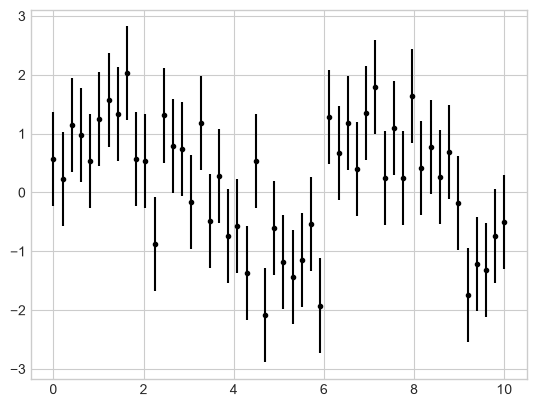

In [9]:
x = np.linspace(0, 10, 50)
dy = 0.8
y = np.sin(x) + dy * np.random.randn(50)

plt.errorbar(x, y, yerr=dy, fmt='.k')

In [10]:
np.sin(np.pi)
#np.sin(np.pi/2)

np.float64(1.2246467991473532e-16)

Here the ``fmt`` is a format code controlling the appearance of lines and points, and has the same syntax as the shorthand used in ``plt.plot``, outlined in [Simple Line Plots](04.01-Simple-Line-Plots.ipynb) and [Simple Scatter Plots](04.02-Simple-Scatter-Plots.ipynb).

In addition to these basic options, the ``errorbar`` function has many options to fine-tune the outputs.
Using these additional options you can easily customize the aesthetics of your errorbar plot.
I often find it helpful, especially in crowded plots, to make the errorbars lighter than the points themselves:

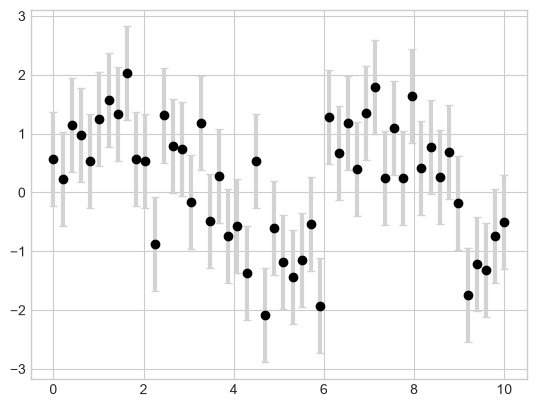

In [11]:
plt.errorbar(x, y, yerr=dy, fmt='o', color = 'black',
            ecolor = 'lightgray', elinewidth=3, capsize=3);

In addition to these options, you can also specify horizontal errorbars (``xerr``), one-sided errorbars, and many other variants.
For more information on the options available, refer to the docstring of ``plt.errorbar``.

# Density and Contour Plots

Sometimes it is useful to display three-dimensional data in two dimensions using contours or color-coded regions.
There are three Matplotlib functions that can be helpful for this task: ``plt.contour`` for contour plots, ``plt.contourf`` for filled contour plots, and ``plt.imshow`` for showing images.
This section looks at several examples of using these. We'll start by setting up the notebook for plotting and importing the functions we will use: 

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import numpy as np

True


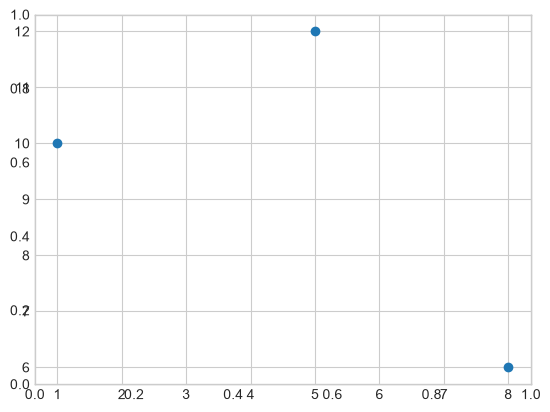

In [13]:
ax1 = plt.axes()
ax2 = plt.axes()

ax3 = plt.gca()
print(ax3 is ax2)

plt.gca().scatter([1, 5, 8], [10, 12, 6])

## Visualizing a Three-Dimensional Function

We'll start by demonstrating a contour plot using a function $z = f(x, y)$, using the following particular choice for $f$ (we've seen this before in [Computation on Arrays: Broadcasting](02.05-Computation-on-arrays-broadcasting.ipynb), when we used it as a motivating example for array broadcasting):

In [ ]:
# esta función recibe una función con 2 números (x, y); por lo que me devuelve la altura
def f(x, y):
    return np.sin(x) ** 10 + np.cos(10 + y * x)* np.cos(x)

A contour plot can be created with the ``plt.contour`` function.
It takes three arguments: a grid of *x* values, a grid of *y* values, and a grid of *z* values.
The *x* and *y* values represent positions on the plot, and the *z* values will be represented by the contour levels.
Perhaps the most straightforward way to prepare such data is to use the ``np.meshgrid`` function, which builds two-dimensional grids from one-dimensional arrays:

In [25]:
# Cada uno de los linspace, me crea un numpy array con 50 puntos equidistantes de 0 a 5, incluido el 5
x = np.linspace(0, 5, 50)
y = np.linspace(2, 6, 70)

# x e y son variables y meshgrid como funciona con 2 objetos, lo que me devuelve es una tupla
# por qué las primeras x e y están en minúsculas y las segundas X, Y están en mayúsculas. x, y en minúsculas son vectores (una dimensión), 
# mientras que X, Y son los ejes, y por lo tanto, tienen varias dimensiones por lo que son matrices.
X, Y = np.meshgrid(x, y)
Z = f(X, Y)



In [26]:
# vemos un numpy array, un vector
x

array([0.        , 0.10204082, 0.20408163, 0.30612245, 0.40816327,
       0.51020408, 0.6122449 , 0.71428571, 0.81632653, 0.91836735,
       1.02040816, 1.12244898, 1.2244898 , 1.32653061, 1.42857143,
       1.53061224, 1.63265306, 1.73469388, 1.83673469, 1.93877551,
       2.04081633, 2.14285714, 2.24489796, 2.34693878, 2.44897959,
       2.55102041, 2.65306122, 2.75510204, 2.85714286, 2.95918367,
       3.06122449, 3.16326531, 3.26530612, 3.36734694, 3.46938776,
       3.57142857, 3.67346939, 3.7755102 , 3.87755102, 3.97959184,
       4.08163265, 4.18367347, 4.28571429, 4.3877551 , 4.48979592,
       4.59183673, 4.69387755, 4.79591837, 4.89795918, 5.        ])

In [27]:
# vemos un numpy array, un vector
y

array([2.        , 2.05797101, 2.11594203, 2.17391304, 2.23188406,
       2.28985507, 2.34782609, 2.4057971 , 2.46376812, 2.52173913,
       2.57971014, 2.63768116, 2.69565217, 2.75362319, 2.8115942 ,
       2.86956522, 2.92753623, 2.98550725, 3.04347826, 3.10144928,
       3.15942029, 3.2173913 , 3.27536232, 3.33333333, 3.39130435,
       3.44927536, 3.50724638, 3.56521739, 3.62318841, 3.68115942,
       3.73913043, 3.79710145, 3.85507246, 3.91304348, 3.97101449,
       4.02898551, 4.08695652, 4.14492754, 4.20289855, 4.26086957,
       4.31884058, 4.37681159, 4.43478261, 4.49275362, 4.55072464,
       4.60869565, 4.66666667, 4.72463768, 4.7826087 , 4.84057971,
       4.89855072, 4.95652174, 5.01449275, 5.07246377, 5.13043478,
       5.1884058 , 5.24637681, 5.30434783, 5.36231884, 5.42028986,
       5.47826087, 5.53623188, 5.5942029 , 5.65217391, 5.71014493,
       5.76811594, 5.82608696, 5.88405797, 5.94202899, 6.        ])

In [28]:
# me devuelve una tupla, y también es un numpy array de 2 dimensiones, que es una matriz. Tengo 50 filas y 50 columnas
X

array([[0.        , 0.10204082, 0.20408163, ..., 4.79591837, 4.89795918,
        5.        ],
       [0.        , 0.10204082, 0.20408163, ..., 4.79591837, 4.89795918,
        5.        ],
       [0.        , 0.10204082, 0.20408163, ..., 4.79591837, 4.89795918,
        5.        ],
       ...,
       [0.        , 0.10204082, 0.20408163, ..., 4.79591837, 4.89795918,
        5.        ],
       [0.        , 0.10204082, 0.20408163, ..., 4.79591837, 4.89795918,
        5.        ],
       [0.        , 0.10204082, 0.20408163, ..., 4.79591837, 4.89795918,
        5.        ]], shape=(70, 50))

In [29]:
X.ndim # me devuelve las dimensiones que tiene la matriz, que en este caso son 2

2

In [ ]:
X.shape # es el tamaño de la matriz (50, 50) porque tiene 50 puntos

(50, 50)

In [30]:
Y

array([[2.        , 2.        , 2.        , ..., 2.        , 2.        ,
        2.        ],
       [2.05797101, 2.05797101, 2.05797101, ..., 2.05797101, 2.05797101,
        2.05797101],
       [2.11594203, 2.11594203, 2.11594203, ..., 2.11594203, 2.11594203,
        2.11594203],
       ...,
       [5.88405797, 5.88405797, 5.88405797, ..., 5.88405797, 5.88405797,
        5.88405797],
       [5.94202899, 5.94202899, 5.94202899, ..., 5.94202899, 5.94202899,
        5.94202899],
       [6.        , 6.        , 6.        , ..., 6.        , 6.        ,
        6.        ]], shape=(70, 50))

In [31]:
Z

array([[-0.83907153, -0.70770261, -0.54270657, ...,  1.0271601 ,
         0.94885696,  0.77317777],
       [-0.83907153, -0.70355462, -0.53302546, ...,  1.00932038,
         0.90260381,  0.69433247],
       [-0.83907153, -0.69938201, -0.52326975, ...,  0.98812877,
         0.85141631,  0.6124076 ],
       ...,
       [-0.83907153, -0.38295365,  0.19958614, ...,  1.03806608,
         0.92124672,  0.61492333],
       [-0.83907153, -0.37751584,  0.21091403, ...,  1.02390152,
         0.87149172,  0.53653665],
       [-0.83907153, -0.37206482,  0.22221239, ...,  1.00526522,
         0.81929387,  0.46823522]], shape=(70, 50))

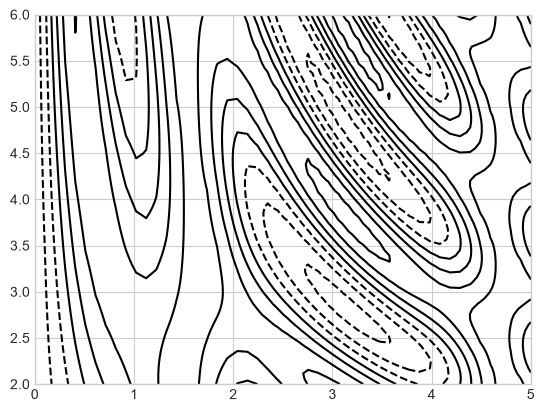

In [ ]:
# tengo líneas contínuas y con guiones. Si no me salgo de la misma línea, estoy a la misma altura. Cada línea es una altura
plt.contour(x, y, Z, colors='black');

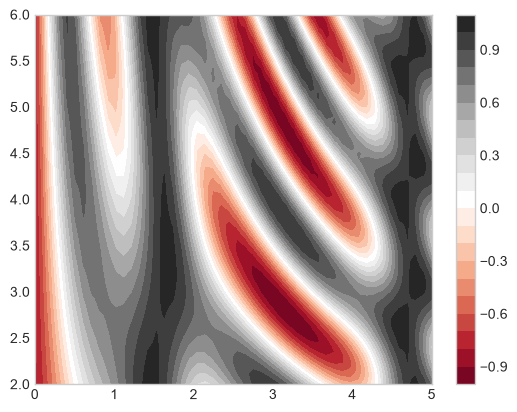

In [33]:
plt.contourf(X, Y, Z, 20, cmap='RdGy')
plt.colorbar()

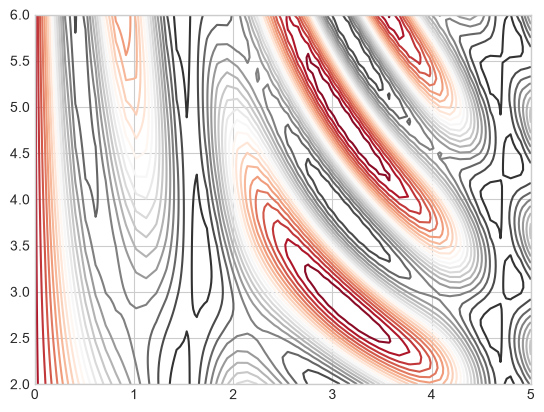

In [35]:
plt.contour(X, Y, Z, 20, cmap='RdGy')

In [8]:
#list(X)

In [9]:
#list(Y)

Now let's look at this with a standard line-only contour plot:

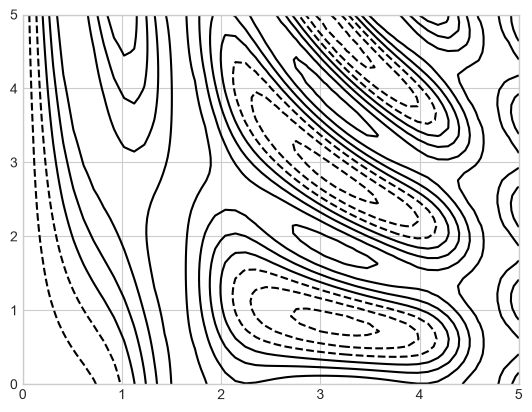

In [6]:
plt.contour(x, y, Z, colors='black');

Notice that by default when a single color is used, negative values are represented by dashed lines, and positive values by solid lines.
Alternatively, the lines can be color-coded by specifying a colormap with the ``cmap`` argument.
Here, we'll also specify that we want more lines to be drawn—20 equally spaced intervals within the data range:

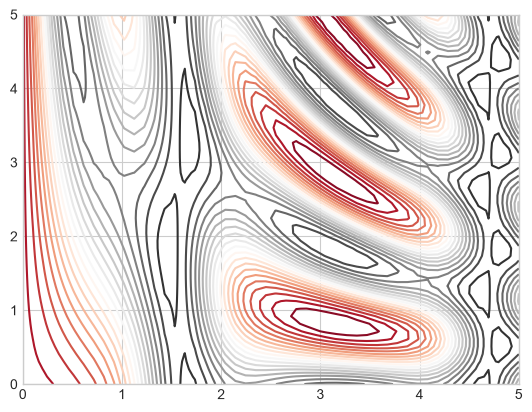

In [11]:
plt.contour(X, Y, Z, 20, cmap='RdGy')

In [12]:
#list(Z)


Here we chose the ``RdGy`` (short for *Red-Gray*) colormap, which is a good choice for centered data.
Matplotlib has a wide range of colormaps available, which you can easily browse in IPython by doing a tab completion on the ``plt.cm`` module:
```
plt.cm.<TAB>
```

Our plot is looking nicer, but the spaces between the lines may be a bit distracting.
We can change this by switching to a **filled contour plot** using the ``plt.contourf()`` function (notice the ``f`` at the end), which uses largely the same syntax as ``plt.contour()``.

Additionally, we'll add a ``plt.colorbar()`` command, which automatically creates an additional axis with labeled color information for the plot:

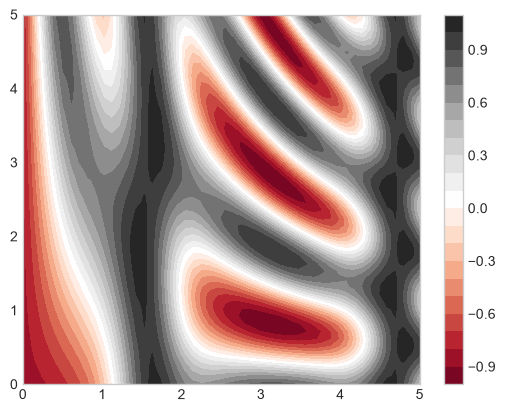

In [13]:
plt.contourf(X, Y, Z, 20, cmap='RdGy')
plt.colorbar()

The colorbar makes it clear that the **black regions are "peaks," while the red regions are "valleys."**

One potential issue with this plot is that it is a bit "splotchy." That is, the **color steps are discrete rather than continuous**, which is not always what is desired.
This could be remedied by setting the number of contours to a very high number, but this results in a rather **inefficient plot**: Matplotlib must render a new polygon for each step in the level.
A better way to handle this is to use the ``plt.imshow()`` function, which interprets a two-dimensional grid of data as an image.

The following code shows this:

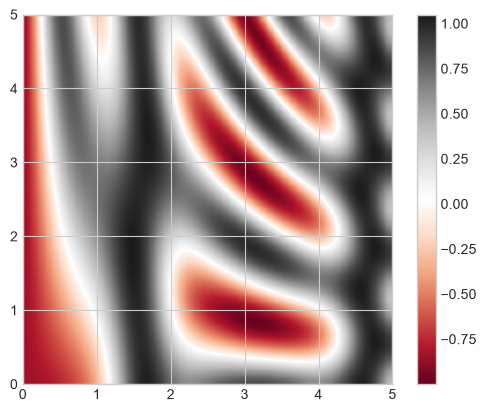

In [14]:
plt.imshow(Z, extent=[0, 5, 0, 5], origin = 'lower',
          cmap='RdGy', interpolation='gaussian')
plt.colorbar()

There are a few potential gotchas with ``imshow()``, however:

- ``plt.imshow()`` doesn't accept an *x* and *y* grid, so you must manually specify the *extent* [*xmin*, *xmax*, *ymin*, *ymax*] of the image on the plot.
- ``plt.imshow()`` by default follows the standard image array definition where the origin is in the upper left, not in the lower left as in most contour plots. This must be changed when showing gridded data.

Finally, it can sometimes be useful to combine contour plots and image plots.
For example, here we'll use a partially transparent background image (with transparency set via the ``alpha`` parameter) and overplot contours with labels on the contours themselves (using the ``plt.clabel()`` function):

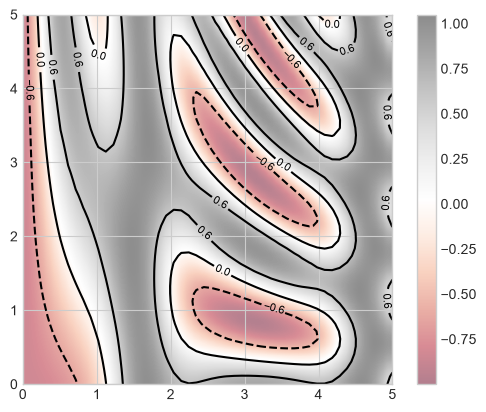

In [15]:
contours = plt.contour(X, Y, Z, 3, colors = 'black')
plt.clabel(contours, inline=True, fontsize=8)

plt.imshow(Z, extent=[0, 5, 0, 5], origin='lower',
          cmap='RdGy', alpha=0.5, interpolation='gaussian')
plt.colorbar()

The combination of these three functions—``plt.contour``, ``plt.contourf``, and ``plt.imshow``—gives nearly limitless possibilities for displaying this sort of three-dimensional data within a two-dimensional plot.
For more information on the options available in these functions, refer to their docstrings.
